In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nicolaswattiez/skillbuilder-data-2009-2010/2012-2013-data-with-predictions-4-final.csv


In [3]:
import pandas as pd
PATH = "/kaggle/input/datasets/nicolaswattiez/skillbuilder-data-2009-2010/2012-2013-data-with-predictions-4-final.csv"
df = pd.read_csv(PATH, nrows=200000, encoding="latin-1")
print(df.shape)
print(df.columns.tolist())
df.head()

(200000, 35)
['problem_log_id', 'skill', 'problem_id', 'user_id', 'assignment_id', 'assistment_id', 'start_time', 'end_time', 'problem_type', 'original', 'correct', 'bottom_hint', 'hint_count', 'actions', 'attempt_count', 'ms_first_response', 'tutor_mode', 'sequence_id', 'student_class_id', 'position', 'type', 'base_sequence_id', 'skill_id', 'teacher_id', 'school_id', 'overlap_time', 'template_id', 'answer_id', 'answer_text', 'first_action', 'problemlogid', 'Average_confidence(FRUSTRATED)', 'Average_confidence(CONFUSED)', 'Average_confidence(CONCENTRATING)', 'Average_confidence(BORED)']


,problem_log_id,skill,problem_id,user_id,assignment_id,assistment_id,start_time,end_time,problem_type,original,...,overlap_time,template_id,answer_id,answer_text,first_action,problemlogid,Average_confidence(FRUSTRATED),Average_confidence(CONFUSED),Average_confidence(CONCENTRATING),Average_confidence(BORED)
0,137792159,NaN,557460,61394,565736,341511,2012-09-28 15:11:27,2012-09-28 15:11:36.856,choose_1,1,...,9852,341511,NaN,she,0,137792159,0.361323,0.0,0.336529,0.000000
1,138083797,Rounding,365981,61394,573819,204043,2012-10-09 11:01:52,2012-10-09 11:02:13.182,algebra,1,...,21175,204043,NaN,74.29,0,138083797,0.361323,0.0,0.766925,0.000000
2,142332619,Multiplication and Division Integers,426415,61394,734130,247525,2013-03-07 10:53:20,2013-03-07 10:53:28.661,algebra,1,...,8645,247525,NaN,00,0,142332619,0.361323,0.0,0.766925,0.442968
3,145939397,Proportion,86686,61394,821352,48081,2013-08-20 19:54:56,2013-08-20 19:55:21.753,algebra,1,...,25728,46362,NaN,3.8,0,145939397,0.775000,0.0,0.766925,0.912281
4,137111284,NaN,399669,76592,557216,227869,2012-09-10 17:20:10,2012-09-10 17:24:56.579,choose_1,1,...,286578,227869,NaN,C (wr - 1)(wr + 1),0,137111284,0.361323,0.0,0.766925,0.000000


Clean data: 377940 answers | 12819 students | 74599 problems | % correct = 0.690
Train: 264717 answers | Test: 113223 answers from 3845 unseen students

===== TRAINING =====
Logistic Regression {'auc': np.float64(0.6988), 'accuracy': 0.7073, 'log_loss': 0.6033}
Gradient Boosting {'auc': np.float64(0.6817), 'accuracy': 0.7066, 'log_loss': 0.8905}
Majority baseline accuracy: 0.689

Best model: Logistic Regression
Confusion matrix [rows=actual wrong/correct, cols=predicted]:
 [[14011 21199]
 [11936 66077]]
              precision    recall  f1-score   support

       wrong      0.540     0.398     0.458     35210
     correct      0.757     0.847     0.800     78013

    accuracy                          0.707    113223
   macro avg      0.649     0.622     0.629    113223
weighted avg      0.690     0.707     0.693    113223


Fairness by response speed (slow = top 25%)
group               answers   actual  predicted     gap     AUC
high (top 25%)        23999    0.685      0.674  -0.012

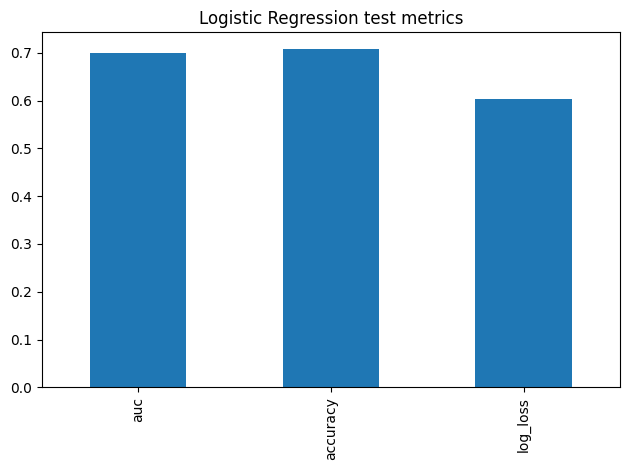

In [4]:
import numpy as np, pandas as pd, json, joblib
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, log_loss, confusion_matrix, classification_report

PATH = "/kaggle/input/datasets/nicolaswattiez/skillbuilder-data-2009-2010/2012-2013-data-with-predictions-4-final.csv"
N_ROWS = 500000          # lower this (e.g. 200000) if it runs slowly
rng = np.random.default_rng(42)

# 1. Load + check columns
df = pd.read_csv(PATH, nrows=N_ROWS, encoding="latin-1", low_memory=False)
need = ["problem_log_id", "user_id", "problem_id", "skill", "correct", "original", "start_time", "ms_first_response"]
missing = [c for c in need if c not in df.columns]
assert not missing, f"Missing columns {missing}. Your columns: {df.columns.tolist()}"

# 2. Clean
df = df[df["original"] == 1].dropna(subset=["correct"])
df["correct"] = (df["correct"] >= 1).astype(int)
df["start_time"] = pd.to_datetime(df["start_time"], errors="coerce")
df = df.dropna(subset=["start_time"]).drop_duplicates("problem_log_id")
df = df.sort_values(["user_id", "start_time"])
df["skill"] = df["skill"].fillna("unknown")
df["ms"] = pd.to_numeric(df["ms_first_response"], errors="coerce").clip(lower=0, upper=300000)
df["ms"] = df["ms"].fillna(df["ms"].median())
df = df[df.groupby("user_id")["user_id"].transform("size") >= 10].reset_index(drop=True)
print(f"Clean data: {len(df)} answers | {df.user_id.nunique()} students | {df.problem_id.nunique()} problems | % correct = {df.correct.mean():.3f}")

# 3. Split by student
ids = df.user_id.unique()
test_ids = set(rng.choice(ids, int(0.3 * len(ids)), replace=False))
df["is_test"] = df.user_id.isin(test_ids)
train_df = df[~df.is_test]
print(f"Train: {len(train_df)} answers | Test: {df.is_test.sum()} answers from {len(test_ids)} unseen students")

# 4. Features (only information known BEFORE the answer)
G = train_df.correct.mean()
def difficulty(key, k=5):
    g = train_df.groupby(key)["correct"].agg(["sum", "count"])
    p = (g["sum"] + G * k) / (g["count"] + k)
    return -np.log(p / (1 - p)), g["count"]
b_item, n_item = difficulty("problem_id")
b_skill, _ = difficulty("skill")
base = -np.log(G / (1 - G))
df["item_difficulty"] = df.problem_id.map(b_item).fillna(base)
df["item_popularity"] = np.log1p(df.problem_id.map(n_item).fillna(0))
df["skill_difficulty"] = df.skill.map(b_skill).fillna(base)
g = df.groupby("user_id")["correct"]
n_prev = g.cumcount()
df["student_prior_acc"] = (g.cumsum() - df.correct + G * 3) / (n_prev + 3)
df["student_experience"] = np.log1p(n_prev)
gs = df.groupby(["user_id", "skill"])["correct"]
df["skill_prior_acc"] = (gs.cumsum() - df.correct + G * 2) / (gs.cumcount() + 2)
df["skill_experience"] = np.log1p(gs.cumcount())
df["recent5_acc"] = g.transform(lambda s: s.shift().rolling(5, min_periods=1).mean()).fillna(G)
df["student_prior_speed"] = np.log1p(df.groupby("user_id")["ms"].transform(lambda s: s.shift().expanding().median())).fillna(np.log1p(df.ms.median()))
FEATURES = ["item_difficulty", "item_popularity", "skill_difficulty", "student_prior_acc", "student_experience",
            "skill_prior_acc", "skill_experience", "recent5_acc", "student_prior_speed"]
tr, te = df[~df.is_test], df[df.is_test].copy()

# 5. Train two models
models = {"Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
          "Gradient Boosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=42)}
res, probs = {}, {}
print("\n===== TRAINING =====")
for name, m in models.items():
    m.fit(tr[FEATURES], tr.correct)
    p = m.predict_proba(te[FEATURES])[:, 1]
    probs[name] = p
    res[name] = {"auc": round(roc_auc_score(te.correct, p), 4), "accuracy": round(accuracy_score(te.correct, p > 0.5), 4),
                 "log_loss": round(log_loss(te.correct, p), 4)}
    print(name, res[name])
base_acc = max(te.correct.mean(), 1 - te.correct.mean())
print("Majority baseline accuracy:", round(base_acc, 4))
best = max(res, key=lambda k: res[k]["auc"])
te["pred"] = probs[best]
joblib.dump({"model": models[best], "features": FEATURES}, "/kaggle/working/trained_model_2012.joblib")
print("\nBest model:", best)
print("Confusion matrix [rows=actual wrong/correct, cols=predicted]:\n", confusion_matrix(te.correct, te.pred > 0.5))
print(classification_report(te.correct, te.pred > 0.5, target_names=["wrong", "correct"], digits=3))

# 6. Fairness: speed groups + predicted-emotion groups (emotions are used ONLY for grouping, not as features)
def top_quarter(series):
    return series.apply(lambda v: "high (top 25%)" if v >= series.quantile(0.75) else "other (75%)")
group_maps = {"response speed (slow = top 25%)": top_quarter(df.groupby("user_id")["ms"].median())}
for label, col in [("frustration", "Average_confidence(FRUSTRATED)"), ("boredom", "Average_confidence(BORED)")]:
    if col in df.columns:
        s = pd.to_numeric(df[col], errors="coerce").groupby(df.user_id).mean()
        if s.nunique() > 3:
            group_maps[f"predicted {label} (high = top 25%)"] = top_quarter(s)
fair = {}
for title, mp in group_maps.items():
    te["grp"] = te.user_id.map(mp)
    print(f"\nFairness by {title}")
    print(f"{'group':18s}{'answers':>9s}{'actual':>9s}{'predicted':>11s}{'gap':>8s}{'AUC':>8s}")
    fair[title] = []
    for name, s in te.groupby("grp"):
        a, p = s.correct.mean(), s.pred.mean()
        u = roc_auc_score(s.correct, s.pred) if s.correct.nunique() > 1 else float("nan")
        fair[title].append({"group": name, "answers": len(s), "actual": round(a, 3), "predicted": round(p, 3), "gap": round(p - a, 3), "auc": round(u, 3)})
        print(f"{name:18s}{len(s):9d}{a:9.3f}{p:11.3f}{p - a:8.3f}{u:8.3f}")

json.dump({"best_model": best, "models": res, "majority_baseline": round(base_acc, 4), "answers": int(len(df)),
           "students": int(df.user_id.nunique()), "fairness": fair}, open("/kaggle/working/training_results_2012.json", "w"), indent=2)
pd.Series(res[best]).plot(kind="bar", title=f"{best} test metrics"); plt.tight_layout(); plt.savefig("/kaggle/working/chart_2012.png")
print("\nSaved to /kaggle/working: trained_model_2012.joblib, training_results_2012.json, chart_2012.png")

In [5]:
import numpy as np, pandas as pd, time
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix

PATH = "/kaggle/input/datasets/nicolaswattiez/skillbuilder-data-2009-2010/2012-2013-data-with-predictions-4-final.csv"
USE = ["problem_log_id", "user_id", "problem_id", "skill", "correct", "original", "start_time", "ms_first_response",
       "template_id", "assignment_id", "assistment_id", "problem_type"]
t = time.time()
df = pd.read_csv(PATH, nrows=400000, usecols=USE, encoding="latin-1")
print("loaded in", round(time.time() - t), "seconds", df.shape)

# clean
df = df[df.original == 1].dropna(subset=["correct"])
df["correct"] = (df.correct >= 1).astype(int)
df["start_time"] = pd.to_datetime(df.start_time, errors="coerce")
df = df.dropna(subset=["start_time"]).drop_duplicates("problem_log_id")
df = df.sort_values(["user_id", "start_time"])
for c in ["skill", "problem_type"]: df[c] = df[c].fillna("unknown")
for c in ["template_id", "assignment_id", "assistment_id"]: df[c] = df[c].fillna(-1)
df["ms"] = pd.to_numeric(df.ms_first_response, errors="coerce").clip(0, 300000)
df["ms"] = df.ms.fillna(df.ms.median())
df = df[df.groupby("user_id")["user_id"].transform("size") >= 10].reset_index(drop=True)

# split students into train 60% / validation 20% / test 20%
rng = np.random.default_rng(42)
ids = rng.permutation(df.user_id.unique()); n = len(ids)
part = {u: "train" for u in ids[:int(.6 * n)]}
part.update({u: "val" for u in ids[int(.6 * n):int(.8 * n)]})
part.update({u: "test" for u in ids[int(.8 * n):]})
df["part"] = df.user_id.map(part)
GM = df[df.part == "train"].correct.mean()        # average % correct in training
print(df.part.value_counts().to_dict(), "| students:", n, "| baseline accuracy:", round(max(GM, 1 - GM), 3))

loaded in 2 seconds (400000, 12)
{'train': 172926, 'test': 57217, 'val': 55619} | students: 10709 | baseline accuracy: 0.693


In [6]:
G = df.groupby("user_id")["correct"]
n_prev = G.cumcount()
df["stu_acc"] = (G.cumsum() - df.correct + GM * 3) / (n_prev + 3)
df["stu_exp"] = np.log1p(n_prev)
gs = df.groupby(["user_id", "skill"])["correct"]
df["skill_acc"] = (gs.cumsum() - df.correct + GM * 2) / (gs.cumcount() + 2)
df["skill_exp"] = np.log1p(gs.cumcount())
df["recent5"] = G.transform(lambda s: s.shift().rolling(5, min_periods=1).mean()).fillna(GM)
df["speed"] = np.log1p(df.groupby("user_id")["ms"].transform(lambda s: s.shift().expanding().median())).fillna(np.log1p(df.ms.median()))
for k in (1, 2, 3):
    df[f"last{k}"] = G.shift(k).fillna(0.5)
df["gap"] = np.log1p(df.groupby("user_id")["start_time"].diff().dt.total_seconds().clip(0, 2592000).fillna(0))
print("history features done")

history features done


In [7]:
def add_difficulty(key, name, k=5):
    tr = df[df.part == "train"]
    base = -np.log(GM / (1 - GM))
    def table(d):
        g = d.groupby(key)["correct"].agg(["sum", "count"])
        p = (g["sum"] + GM * k) / (g["count"] + k)
        return -np.log(p / (1 - p))
    out = pd.Series(base, index=df.index, dtype=float)
    for fit_i, hold_i in GroupKFold(5).split(tr, groups=tr.user_id):
        out.loc[tr.index[hold_i]] = tr.iloc[hold_i][key].map(table(tr.iloc[fit_i])).fillna(base).values
    other = df.part != "train"
    out.loc[other] = df.loc[other, key].map(table(tr)).fillna(base).values
    df[name] = out

for key, name in [("problem_id", "d_problem"), ("skill", "d_skill"), ("template_id", "d_template"),
                  ("assignment_id", "d_assign"), ("assistment_id", "d_assistment"), ("problem_type", "d_ptype")]:
    add_difficulty(key, name)

def run(features, model=None):
    m = model or make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    tr, va = df[df.part == "train"], df[df.part == "val"]
    m.fit(tr[features], tr.correct)
    return m, roc_auc_score(va.correct, m.predict_proba(va[features])[:, 1])

S1 = ["d_problem", "d_skill", "stu_acc", "stu_exp", "skill_acc", "skill_exp", "recent5", "speed"]
S2 = S1 + ["d_template", "d_assign", "d_assistment", "d_ptype"]
S3 = S2 + ["last1", "last2", "last3", "gap"]
print("Old result (first version): validation AUC about 0.699")
for name, f in [("Step 1: leak-free problem + skill difficulty", S1),
                ("Step 2: + group difficulties (template, assignment, assistment, type)", S2),
                ("Step 3: + recent answers and time gap", S3)]:
    print(f"{name:75s} AUC = {run(f)[1]:.4f}")

Old result (first version): validation AUC about 0.699
Step 1: leak-free problem + skill difficulty                                AUC = 0.7015
Step 2: + group difficulties (template, assignment, assistment, type)       AUC = 0.7229
Step 3: + recent answers and time gap                                       AUC = 0.7233


In [8]:
hgb = HistGradientBoostingClassifier(learning_rate=0.05, max_depth=6, max_iter=500, min_samples_leaf=100,
                                     l2_regularization=1.0, early_stopping=True, random_state=42)
m_lr, auc_lr = run(S3)
m_gb, auc_gb = run(S3, hgb)
print(f"Validation AUC  Logistic Regression = {auc_lr:.4f} | Gradient Boosting = {auc_gb:.4f}")
best = m_gb if auc_gb > auc_lr else m_lr
te = df[df.part == "test"].copy()
te["pred"] = best.predict_proba(te[S3])[:, 1]
base_acc = max(te.correct.mean(), 1 - te.correct.mean())
print("\n=== FINAL TEST (students never used before) ===")
print(f"AUC = {roc_auc_score(te.correct, te.pred):.4f} | accuracy = {accuracy_score(te.correct, te.pred > .5):.4f} | guessing baseline = {base_acc:.4f}")
print("Confusion matrix [rows=actual wrong/correct, cols=predicted]:\n", confusion_matrix(te.correct, te.pred > .5))
med = df.groupby("user_id")["ms"].median()
slow = med >= med.quantile(.75)
te["group"] = te.user_id.map(slow).map({True: "slow (top 25%)", False: "other (75%)"})
print("\nFairness by response speed")
for name, s in te.groupby("group"):
    print(f"{name:16s} answers={len(s):7d} actual={s.correct.mean():.3f} predicted={s.pred.mean():.3f} gap={s.pred.mean() - s.correct.mean():+.3f} AUC={roc_auc_score(s.correct, s.pred):.3f}")

Validation AUC  Logistic Regression = 0.7233 | Gradient Boosting = 0.7260

=== FINAL TEST (students never used before) ===
AUC = 0.7249 | accuracy = 0.7280 | guessing baseline = 0.6934
Confusion matrix [rows=actual wrong/correct, cols=predicted]:
 [[ 5084 12456]
 [ 3107 36570]]

Fairness by response speed
other (75%)      answers=  45401 actual=0.697 predicted=0.698 gap=+0.001 AUC=0.729
slow (top 25%)   answers=  11816 actual=0.682 predicted=0.681 gap=-0.000 AUC=0.707


In [9]:
# --- more features, all from PAST rows only
G = df.groupby("user_id")["correct"]
df["ewm_acc"] = G.transform(lambda s: s.shift().ewm(alpha=0.3).mean()).fillna(GM)
df["last10"] = G.transform(lambda s: s.shift().rolling(10, min_periods=1).mean()).fillna(GM)
ga = df.groupby(["user_id", "assignment_id"])["correct"]
df["asg_acc"] = (ga.cumsum() - df.correct + GM * 2) / (ga.cumcount() + 2)
df["asg_pos"] = np.log1p(ga.cumcount())
gt = df.groupby(["user_id", "problem_type"])["correct"]
df["ptype_acc"] = (gt.cumsum() - df.correct + GM * 2) / (gt.cumcount() + 2)
df["speed5"] = np.log1p(df.groupby("user_id")["ms"].transform(lambda s: s.shift().rolling(5, min_periods=1).mean())).fillna(np.log1p(df.ms.median()))
df["hour"] = df.start_time.dt.hour
df["dow"] = df.start_time.dt.dayofweek
df["days_since_first"] = np.log1p((df.start_time - df.groupby("user_id")["start_time"].transform("min")).dt.total_seconds() / 86400)

S4 = S3 + ["ewm_acc", "last10", "asg_acc", "asg_pos", "ptype_acc", "speed5", "hour", "dow", "days_since_first"]
hgb2 = HistGradientBoostingClassifier(learning_rate=0.05, max_depth=6, max_iter=600, min_samples_leaf=100,
                                      l2_regularization=1.0, early_stopping=True, random_state=42)
m_lr, auc_lr = run(S4)
m_gb, auc_gb = run(S4, hgb2)
print(f"Validation AUC (S3 was 0.7260)  LR = {auc_lr:.4f} | GB = {auc_gb:.4f}")

va, te = df[df.part == "val"], df[df.part == "test"].copy()
pv = (m_lr.predict_proba(va[S4])[:, 1] + m_gb.predict_proba(va[S4])[:, 1]) / 2    # average of 2 models
cuts = np.arange(0.40, 0.81, 0.01)
cut = cuts[np.argmax([accuracy_score(va.correct, pv > c) for c in cuts])]          # chosen on VALIDATION only
te["pred"] = (m_lr.predict_proba(te[S4])[:, 1] + m_gb.predict_proba(te[S4])[:, 1]) / 2
base_acc = max(te.correct.mean(), 1 - te.correct.mean())
print("\n=== FINAL TEST ===")
print(f"AUC = {roc_auc_score(te.correct, te.pred):.4f} | accuracy at 0.5 = {accuracy_score(te.correct, te.pred > .5):.4f} | "
      f"accuracy at chosen cut-off {cut:.2f} = {accuracy_score(te.correct, te.pred > cut):.4f} | guessing baseline = {base_acc:.4f}")
print("Confusion matrix at chosen cut-off [rows=actual wrong/correct]:\n", confusion_matrix(te.correct, te.pred > cut))

Validation AUC (S3 was 0.7260)  LR = 0.7246 | GB = 0.7265

=== FINAL TEST ===
AUC = 0.7258 | accuracy at 0.5 = 0.7300 | accuracy at chosen cut-off 0.50 = 0.7300 | guessing baseline = 0.6934
Confusion matrix at chosen cut-off [rows=actual wrong/correct]:
 [[ 5192 12348]
 [ 3102 36575]]


In [10]:
import json, joblib, os
te["pred"] = (m_lr.predict_proba(te[S4])[:, 1] + m_gb.predict_proba(te[S4])[:, 1]) / 2
med = df.groupby("user_id")["ms"].median()
te["grp"] = te.user_id.map(med >= med.quantile(.75)).map({True: "slow (top 25%)", False: "other (75%)"})
fair = [{"group": g, "answers": int(len(s)), "actual": round(float(s.correct.mean()), 3),
         "predicted": round(float(s.pred.mean()), 3), "auc": round(float(roc_auc_score(s.correct, s.pred)), 3)}
        for g, s in te.groupby("grp")]
result = {"dataset": "ASSISTments 2012-2013 (first 400,000 rows)", "students": int(df.user_id.nunique()),
          "answers": int(len(df)), "test_auc": round(float(roc_auc_score(te.correct, te.pred)), 4),
          "test_accuracy": round(float(accuracy_score(te.correct, te.pred > cut)), 4),
          "guessing_baseline": round(float(max(te.correct.mean(), 1 - te.correct.mean())), 4),
          "confusion_matrix": confusion_matrix(te.correct, te.pred > cut).tolist(),
          "fairness_by_speed": fair, "features": S4}
json.dump(result, open("/kaggle/working/final_results_2012.json", "w"), indent=2)
joblib.dump({"models": [m_lr, m_gb], "features": S4, "cutoff": float(cut)}, "/kaggle/working/final_model_2012.joblib")
print(json.dumps(result, indent=2)); print(os.listdir("/kaggle/working"))

{
  "dataset": "ASSISTments 2012-2013 (first 400,000 rows)",
  "students": 10709,
  "answers": 285762,
  "test_auc": 0.7258,
  "test_accuracy": 0.73,
  "guessing_baseline": 0.6934,
  "confusion_matrix": [
    [
      5192,
      12348
    ],
    [
      3102,
      36575
    ]
  ],
  "fairness_by_speed": [
    {
      "group": "other (75%)",
      "answers": 45401,
      "actual": 0.697,
      "predicted": 0.696,
      "auc": 0.73
    },
    {
      "group": "slow (top 25%)",
      "answers": 11816,
      "actual": 0.682,
      "predicted": 0.681,
      "auc": 0.709
    }
  ],
  "features": [
    "d_problem",
    "d_skill",
    "stu_acc",
    "stu_exp",
    "skill_acc",
    "skill_exp",
    "recent5",
    "speed",
    "d_template",
    "d_assign",
    "d_assistment",
    "d_ptype",
    "last1",
    "last2",
    "last3",
    "gap",
    "ewm_acc",
    "last10",
    "asg_acc",
    "asg_pos",
    "ptype_acc",
    "speed5",
    "hour",
    "dow",
    "days_since_first"
  ]
}
['trained_model